# Predict New York City Airbnb Prices — Linear Regression Project

**Dataset:** "New York City Airbnb Open Data" by AB NYC (Kaggle). Place
`AB_NYC_2019.csv` in the same folder as this notebook before running.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
DATA_PATH = "AB_NYC_2019.csv"


## Step 1: Exploratory Data Analysis (EDA) & Data Auditing

In [2]:
# Task 1.1: Load the dataset and inspect shape, columns, and data types
df = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print()
df.info()


Shape (rows, columns): (48895, 16)

Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null 

In [3]:
# Task 1.2: Identify numerical (discrete/continuous) vs. categorical (nominal/ordinal) columns
numerical_continuous = ['price', 'latitude', 'longitude', 'reviews_per_month']
numerical_discrete = ['minimum_nights', 'number_of_reviews',
                       'calculated_host_listings_count', 'availability_365']
categorical_nominal = ['neighbourhood_group', 'neighbourhood', 'room_type']

print("Numerical (continuous):", numerical_continuous)
print("Numerical (discrete):  ", numerical_discrete)
print("Categorical (nominal): ", categorical_nominal)


Numerical (continuous): ['price', 'latitude', 'longitude', 'reviews_per_month']
Numerical (discrete):   ['minimum_nights', 'number_of_reviews', 'calculated_host_listings_count', 'availability_365']
Categorical (nominal):  ['neighbourhood_group', 'neighbourhood', 'room_type']


In [4]:
# Task 1.3: Check for missing values and calculate percentages
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_report = missing_report[missing_report['missing_count'] > 0].sort_values(
    'missing_count', ascending=False)
missing_report


,missing_count,missing_pct
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


## Step 2: Data Cleaning & Handling Missing Values

In [5]:
# Task 2.1: last_review is a date string with 10,000+ missing values.
# It isn't numeric and out of scope to engineer here, so we drop it.
df_clean = df.drop(columns=['last_review'])
print("Dropped 'last_review'. New shape:", df_clean.shape)


Dropped 'last_review'. New shape: (48895, 15)


In [6]:
# Task 2.2: reviews_per_month is missing exactly when number_of_reviews == 0
missing_rpm = df_clean['reviews_per_month'].isnull()
print("Rows missing reviews_per_month:", missing_rpm.sum())
print("Of those, rows with number_of_reviews == 0:",
      (df_clean.loc[missing_rpm, 'number_of_reviews'] == 0).sum())

# No reviews logically means 0 reviews per month, so 0 is the correct fill value.
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)
print("Remaining missing reviews_per_month:", df_clean['reviews_per_month'].isnull().sum())


Rows missing reviews_per_month: 10052
Of those, rows with number_of_reviews == 0: 10052
Remaining missing reviews_per_month: 0


In [7]:
# Task 2.3: Drop identifier columns that carry no mathematical signal
id_like_cols = ['id', 'name', 'host_id', 'host_name']
df_clean = df_clean.drop(columns=[c for c in id_like_cols if c in df_clean.columns])
print("Remaining columns:", list(df_clean.columns))


Remaining columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


## Step 3: Outlier Identification & Treatment

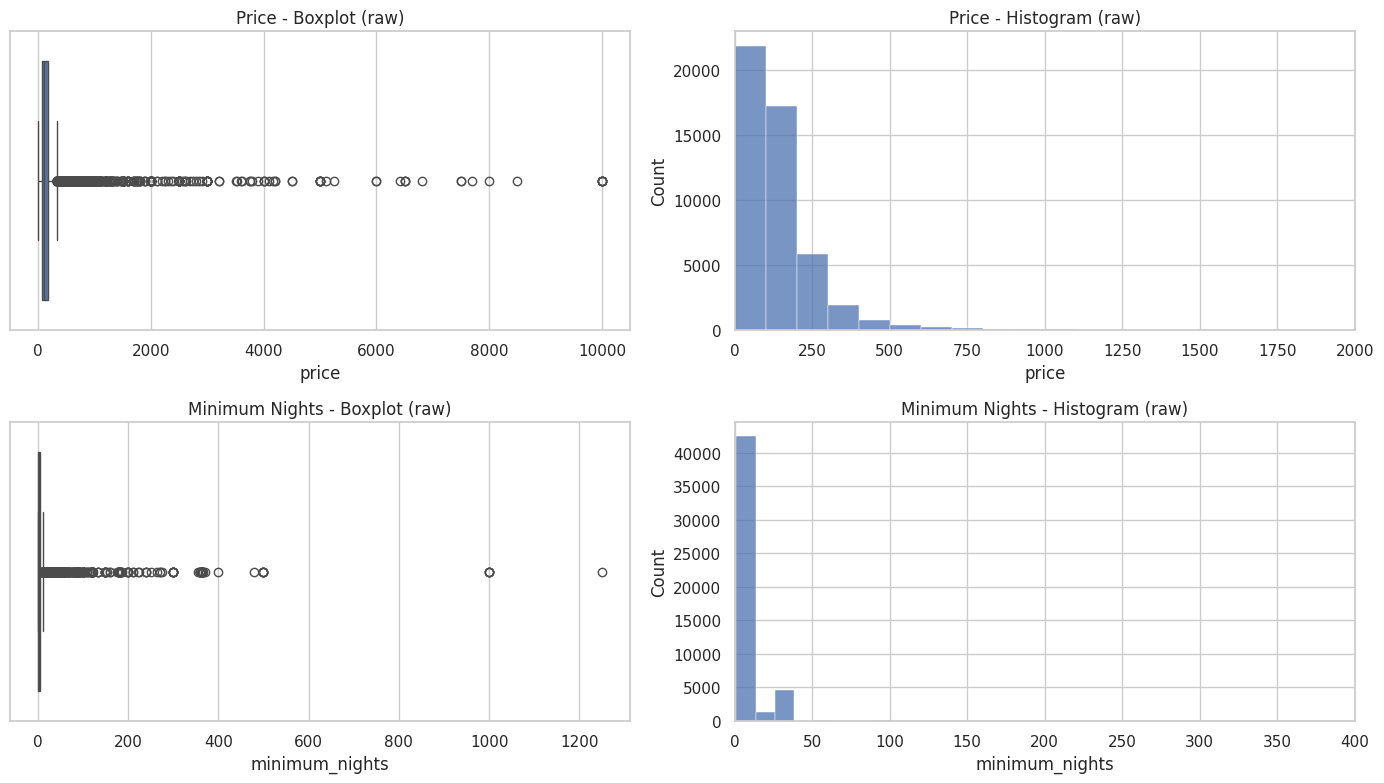

In [8]:
# Task 3.1: Boxplots/histograms for price and minimum_nights
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(x=df_clean['price'], ax=axes[0, 0])
axes[0, 0].set_title('Price - Boxplot (raw)')

sns.histplot(df_clean['price'], bins=100, ax=axes[0, 1])
axes[0, 1].set_title('Price - Histogram (raw)')
axes[0, 1].set_xlim(0, 2000)

sns.boxplot(x=df_clean['minimum_nights'], ax=axes[1, 0])
axes[1, 0].set_title('Minimum Nights - Boxplot (raw)')

sns.histplot(df_clean['minimum_nights'], bins=100, ax=axes[1, 1])
axes[1, 1].set_title('Minimum Nights - Histogram (raw)')
axes[1, 1].set_xlim(0, 400)

plt.tight_layout()
plt.show()


In [9]:
# Task 3.2: 95th-percentile capping/trimming strategy
price_cap = df_clean['price'].quantile(0.95)
nights_cap = df_clean['minimum_nights'].quantile(0.95)
print(f"95th percentile price cap: ${price_cap:.2f}")
print(f"95th percentile minimum_nights cap: {nights_cap:.0f} nights")

before_rows = len(df_clean)
df_clean = df_clean[
    (df_clean['price'] > 0) &
    (df_clean['price'] <= price_cap) &
    (df_clean['minimum_nights'] <= nights_cap)
].reset_index(drop=True)

print(f"Rows before: {before_rows}, after: {len(df_clean)}, "
      f"removed: {before_rows - len(df_clean)}")


95th percentile price cap: $355.00
95th percentile minimum_nights cap: 30 nights
Rows before: 48895, after: 45748, removed: 3147


## Step 4: Feature Selection & Categorical Encoding

**Task 4.1:** `neighbourhood` has 200+ unique values. One-hot encoding it would add
200+ sparse columns relative to the number of rows, causing the **Curse of
Dimensionality**: many categories end up with too few listings to learn a stable
coefficient, the model overfits to neighbourhood-specific noise, and it becomes
harder to interpret. `neighbourhood_group` (5 values) captures most of the same
location signal without that cost, so we drop `neighbourhood` and keep
`neighbourhood_group`.

In [10]:
# Task 4.1: Drop the high-cardinality neighbourhood column
print("Unique 'neighbourhood':", df_clean['neighbourhood'].nunique())
print("Unique 'neighbourhood_group':", df_clean['neighbourhood_group'].nunique())

df_model = df_clean.drop(columns=['neighbourhood'])


Unique 'neighbourhood': 219
Unique 'neighbourhood_group': 5


In [11]:
# Task 4.2: One-Hot Encode remaining categoricals, dropping first to avoid the Dummy Variable Trap
df_model = pd.get_dummies(df_model, columns=['neighbourhood_group', 'room_type'],
                           drop_first=True)
print("Shape after encoding:", df_model.shape)
df_model.head()


Shape after encoding: (45748, 14)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,True,False,False,False,True,False
1,40.75362,-73.98377,225,1,45,0.38,2,355,False,True,False,False,False,False
2,40.80902,-73.94190,150,3,0,0.00,1,365,False,True,False,False,True,False
3,40.68514,-73.95976,89,1,270,4.64,1,194,True,False,False,False,False,False
4,40.79851,-73.94399,80,10,9,0.10,1,0,False,True,False,False,False,False


## Step 5: Feature-Target Separation & Validation Split

In [12]:
# Task 5.1: Separate features (X) and target (y)
X = df_model.drop(columns=['price'])
y = df_model['price']
print("X shape:", X.shape, "| y shape:", y.shape)


X shape: (45748, 13) | y shape: (45748,)


In [13]:
# Task 5.2: 80/20 train-test split with a fixed reproducibility seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (36598, 13) | Test: (9150, 13)


## Step 6: Model Training & Evaluation

In [14]:
# Task 6.1: Initialize and fit a standard Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained.")


Model trained.


In [15]:
# Task 6.2: Generate predictions on the held-out test set
y_pred = model.predict(X_test)


In [16]:
# Task 6.3: Calculate R^2, MAE, MSE, RMSE
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-Squared (R^2):            {r2:.4f}")
print(f"Mean Absolute Error (MAE):  ${mae:.2f}")
print(f"Mean Squared Error (MSE):   {mse:.2f}")
print(f"Root Mean Squared Error:    ${rmse:.2f}")


R-Squared (R^2):            0.4868
Mean Absolute Error (MAE):  $38.32
Mean Squared Error (MSE):   2760.62
Root Mean Squared Error:    $52.54


## Step 7: Residual Analysis & Interpretation

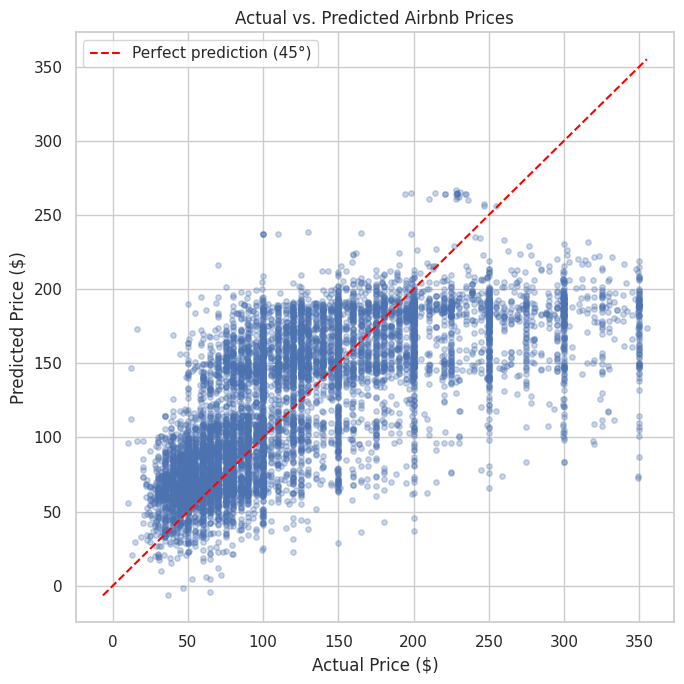

In [17]:
# Task 7.1: Actual vs. Predicted Prices with a 45-degree "perfect prediction" line
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=15)

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color='red', linestyle='--', label='Perfect prediction (45°)')

plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs. Predicted Airbnb Prices')
plt.legend()
plt.tight_layout()
plt.show()


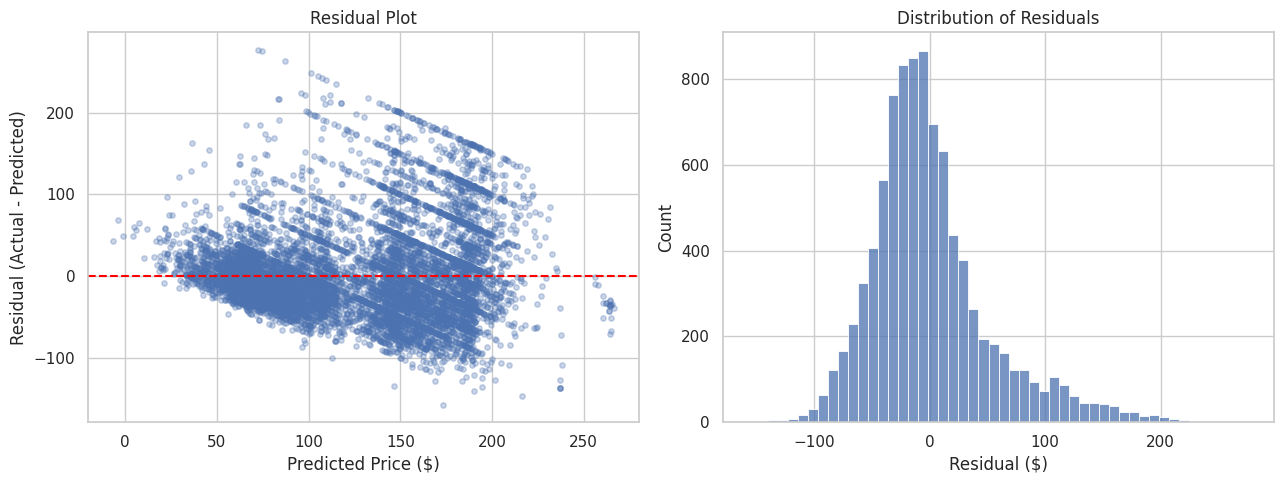

In [18]:
# Task 7.2: Residual plot and error distribution
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred, residuals, alpha=0.3, s=15)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Price ($)')
axes[0].set_ylabel('Residual (Actual - Predicted)')
axes[0].set_title('Residual Plot')

sns.histplot(residuals, bins=50, ax=axes[1])
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual ($)')

plt.tight_layout()
plt.show()


In [19]:
# Task 7.3: Does the model perform better on cheap or expensive listings?
error_df = pd.DataFrame({'actual': y_test, 'predicted': y_pred})
error_df['abs_error'] = (error_df['actual'] - error_df['predicted']).abs()
error_df['price_tier'] = pd.qcut(error_df['actual'], q=4,
                                  labels=['Low', 'Mid-Low', 'Mid-High', 'High'])

tier_summary = error_df.groupby('price_tier', observed=True).agg(
    avg_actual_price=('actual', 'mean'),
    avg_abs_error=('abs_error', 'mean'),
    n_listings=('actual', 'size')
)
tier_summary


,avg_actual_price,avg_abs_error,n_listings
price_tier,,,
Low,50.055652,26.211232,2300
Mid-Low,85.156561,31.687319,2408
Mid-High,132.726262,31.324502,2159
High,229.903198,64.112438,2283


**Answer:** the model performs better on cheap-to-mid-range listings than on
expensive ones. Average absolute error rises as actual price rises, because most
NYC Airbnbs cluster in the lower price bands (more training examples there), while
expensive listings are rarer and priced on factors not in this dataset (exact
views, finishes, brand), giving the model less signal to work with.